# KSH gazdasági paneladatbázis előkészítése

A notebook célja a Központi Statisztikai Hivatal által közzétett
területi és negyedéves gazdasági mutatók beolvasása, tisztítása,
összekapcsolása és egységes paneladatbázissá alakítása.

A vizsgálat 2018 és 2025 közötti negyedéves adatokat, Budapestet
és a 19 vármegyét tartalmazza.

A notebook kimenete:
`processed/KSH_Panel_FINAL_2018_2025.csv`

In [1]:
# CSOMAGOK ÉS FÁJLÚTVONALAK

import re
from functools import reduce
from pathlib import Path
import numpy as np
import pandas as pd
BASE_DIR = Path.cwd()
RAW = BASE_DIR / "raw"
OUT = BASE_DIR / "processed"
OUT.mkdir(parents=True,exist_ok=True)

print("Munkakönyvtár:",BASE_DIR)
print("Nyers adatok helye:",RAW)
print("Feldolgozott adatok helye:",OUT)


UNEMP_FILE = (RAW/ "stadat-mun0171-20.2.2.5-hu.csv")
GROSS_FILE1 = (RAW/ "stadat-mun0175-20.9.2.4-hu.csv")
GROSS_FILE2 = (RAW/ "stadat-mun0206-20.2.2.9-hu.csv")
LF_WORK = (RAW/ "stadat-mun0172-20.2.2.6-hu.csv")
ACTIVE_POP = (RAW/ "stadat-mun0161-20.2.2.1-hu.csv")

source_files = [UNEMP_FILE,GROSS_FILE1,GROSS_FILE2,LF_WORK,ACTIVE_POP]

missing_source_files = [
    file
    for file in source_files
    if not file.exists()
]

if missing_source_files:
    raise FileNotFoundError(
        "Hiányzó nyers adatfájlok:\n"
        +
        "\n".join(
            str(file)
            for file in missing_source_files
        )
    )
print("Minden szükséges nyers adatfájl elérhető.")

Munkakönyvtár: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12
Nyers adatok helye: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\raw
Feldolgozott adatok helye: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed
Minden szükséges nyers adatfájl elérhető.


In [2]:
# 1.szám-tisztító
def clean_numeric(val):
    if pd.isna(val): return np.nan
    if isinstance(val, str):
        val = val.replace(' ', '').replace('\xa0', '').replace(',', '.')
        try: return float(val)
        except ValueError: return np.nan
    return float(val)

# 2.Dátum felismerő
def parse_date(val):
    val = str(val).upper()
    match = re.search(r'(\d{4})', val)
    if not match: return pd.NaT
    y = int(match.group(1))
    
    if 'MÁRCIUS' in val: return pd.Timestamp(y, 1, 1)
    if 'JÚNIUS' in val: return pd.Timestamp(y, 4, 1)
    if 'SZEPTEMBER' in val: return pd.Timestamp(y, 7, 1)
    if 'DECEMBER' in val: return pd.Timestamp(y, 10, 1)
    
    if 'I. FÉLÉV' in val: return pd.Timestamp(y, 4, 1) 
    if re.search(r'I[–\-—_]III', val): return pd.Timestamp(y, 7, 1) 
    if re.search(r'I[–\-—_]IV', val): return pd.Timestamp(y, 10, 1) 
    
    if 'III.' in val: return pd.Timestamp(y, 7, 1)
    if 'IV.' in val: return pd.Timestamp(y, 10, 1)
    if 'II.' in val: return pd.Timestamp(y, 4, 1)
    if 'I.' in val: return pd.Timestamp(y, 1, 1)
    
    return pd.NaT

ksh_encoding = 'windows-1250'

# 3. NYERS ADATOK BEOLVASÁSA ÉS DÁTUM KONVERZIÓ

# Munkanélküliség
df_171 = pd.read_csv(UNEMP_FILE, sep=';', header=1, encoding=ksh_encoding)
if 'Területi egység szintje' in df_171.columns: df_171.drop(columns=['Területi egység szintje'], inplace=True)
df_171 = df_171.melt(id_vars=['Területi egység neve'], var_name='RawDate', value_name='Munkanélküliségi_ráta_%')
df_171['Dátum'] = df_171['RawDate'].apply(parse_date)
df_171['Munkanélküliségi_ráta_%'] = df_171['Munkanélküliségi_ráta_%'].apply(clean_numeric)
df_171 = df_171.dropna(subset=['Dátum', 'Munkanélküliségi_ráta_%'])[['Dátum', 'Területi egység neve', 'Munkanélküliségi_ráta_%']]

# Álláskeresők
df_172 = pd.read_csv(LF_WORK, sep=';', header=1, encoding=ksh_encoding)
if 'Területi egység szintje' in df_172.columns: df_172.drop(columns=['Területi egység szintje'], inplace=True)
df_172 = df_172.melt(id_vars=['Területi egység neve'], var_name='RawDate', value_name='Álláskeresők_száma')
df_172['Dátum'] = df_172['RawDate'].apply(parse_date)
df_172['Álláskeresők_száma'] = df_172['Álláskeresők_száma'].apply(clean_numeric)
df_172 = df_172.dropna(subset=['Dátum', 'Álláskeresők_száma'])[['Dátum', 'Területi egység neve', 'Álláskeresők_száma']]

# Foglalkoztatottak (Aktivitás)
df_161_raw = pd.read_csv(ACTIVE_POP, sep=';', header=1, encoding=ksh_encoding)
cleaned_data_161 = []
current_period = None
for index, row in df_161_raw.iterrows():
    if pd.isna(row.get('Területi egység szintje')) and isinstance(row.get('Területi egység neve'), str):
        current_period = row['Területi egység neve'].strip()
    elif pd.notna(row.get('Területi egység szintje')):
        r_dict = row.to_dict()
        r_dict['RawDate'] = current_period
        cleaned_data_161.append(r_dict)
df_161 = pd.DataFrame(cleaned_data_161)
df_161['Dátum'] = df_161['RawDate'].apply(parse_date)
df_161['Foglalkoztatottak, ezer fő'] = df_161['Foglalkoztatottak, ezer fő'].apply(clean_numeric)
df_161 = df_161.dropna(subset=['Dátum', 'Foglalkoztatottak, ezer fő'])[['Dátum', 'Területi egység neve', 'Foglalkoztatottak, ezer fő']]

# Bérek (Függvény a két bértáblához)
def process_wage(filepath, val_name):
    df = pd.read_csv(
        filepath,
        sep=";",
        header=1,
        encoding=ksh_encoding
    )
    terulet_oszlop = "Területi egység neve"
    sorcimkek = (
        df[terulet_oszlop]
        .astype(str)
        .str.strip()
    )

    # A forintban közölt bruttó átlagkereseti blokk kezdete
    kezdo_index = df.index[
        sorcimkek.eq("Bruttó átlagkereset, forint")
    ][0]
    # A következő, már indexértékeket tartalmazó blokk kezdete
    veg_indexek = df.index[
        (df.index > kezdo_index)
        & sorcimkek.str.startswith(
            "Az előző év azonos időszaka",
            na=False
        )
    ]

    if len(veg_indexek) > 0:
        veg_index = veg_indexek[0]
    else:
        veg_index = df.index.max() + 1

    # Csak a forintban közölt kereseti sorok megtartása
    df = df.loc[
        (df.index > kezdo_index)
        & (df.index < veg_index)
    ].copy()

    if "Területi egység szintje" in df.columns:
        df = df.drop(
            columns=["Területi egység szintje"]
        )

    df_melt = df.melt(
        id_vars=[terulet_oszlop],
        var_name="RawDate",
        value_name=val_name
    )

    df_melt["Dátum"] = (
        df_melt["RawDate"]
        .apply(parse_date)
    )

    df_melt[val_name] = (
        df_melt[val_name]
        .apply(clean_numeric)
    )

    df_melt[terulet_oszlop] = (
        df_melt[terulet_oszlop]
        .astype(str)
        .str.strip()
    )

    return (
        df_melt
        .dropna(subset=["Dátum", val_name])
        [
            [
                "Dátum",
                terulet_oszlop,
                val_name
            ]
        ]
    )
    
df_175 = process_wage(GROSS_FILE1, 'Bruttó_átlagkereset_Archív')
df_206 = process_wage(GROSS_FILE2, 'Bruttó_átlagkereset_Új')


# 4. ÖSSZEFŰZÉS, TISZTÍTÁS ÉS FEATURE ENGINEERING

dataframes = [df_171, df_172, df_175, df_206, df_161]
for df in dataframes:
    df['Területi egység neve'] = df['Területi egység neve'].astype(str).str.strip()

# Outer Join
df_master = reduce(lambda left, right: pd.merge(left, right, on=['Dátum', 'Területi egység neve'], how='outer'), dataframes)

# Bérek összevonása
# A két KSH bérforrás kumulált adatokat tartalmaz
df_master["Bruttó_átlagkereset_kumulált_HUF"] = (
    df_master["Bruttó_átlagkereset_Új"]
    .fillna(df_master["Bruttó_átlagkereset_Archív"])
)

df_master = df_master.drop(
    columns=[
        "Bruttó_átlagkereset_Új",
        "Bruttó_átlagkereset_Archív"
    ],
    errors="ignore"
)

# Vármegyék szűrése
cel_teruletek = ['Budapest', 'Pest', 'Fejér', 'Komárom-Esztergom', 'Veszprém', 'Győr-Moson-Sopron', 'Vas', 'Zala',
                  'Baranya', 'Somogy', 'Tolna', 'Borsod-Abaúj-Zemplén', 'Heves', 'Nógrád', 'Hajdú-Bihar', 'Jász-Nagykun-Szolnok',
                    'Szabolcs-Szatmár-Bereg', 'Bács-Kiskun', 'Békés', 'Csongrád-Csanád', 'Csongrád']
df_filtered = df_master[df_master['Területi egység neve'].isin(cel_teruletek)].copy()
df_filtered['Területi egység neve'] = df_filtered['Területi egység neve'].replace({'Csongrád': 'Csongrád-Csanád'})

# 2018 - 2025 szűrés
df_filtered = df_filtered[(df_filtered['Dátum'].dt.year >= 2018) & (df_filtered['Dátum'].dt.year <= 2025)]

df_filtered = df_filtered.sort_values(
    ["Területi egység neve", "Dátum"]
).reset_index(drop=True)

df_filtered["Év"] = df_filtered["Dátum"].dt.year
df_filtered["Negyedév"] = df_filtered["Dátum"].dt.quarter

# Előző kumulált érték, ugyanazon terület és ugyanazon év szerint
df_filtered["Előző_kumulált_bér"] = (
    df_filtered
    .groupby(
        ["Területi egység neve", "Év"]
    )["Bruttó_átlagkereset_kumulált_HUF"]
    .shift(1)
)

q = df_filtered["Negyedév"]
cum_wage = df_filtered["Bruttó_átlagkereset_kumulált_HUF"]
previous_cum_wage = df_filtered["Előző_kumulált_bér"]

# Q1 esetén a kumulált érték maga a negyedéves érték.
# Q2–Q4 esetén algebrai de-kumulálás.
df_filtered["Bruttó_átlagkereset_HUF"] = np.where(
    q == 1,
    cum_wage,
    q * cum_wage
    - (q - 1) * previous_cum_wage
)
# Duplikált terület–dátum kulcs nem lehet
assert not df_filtered.duplicated(
    ["Dátum", "Területi egység neve"]
).any(), "Duplikált terület–dátum kulcs található."

# Minden terület–év kombinációhoz 4 negyedév szükséges
quarter_counts = (
    df_filtered
    .groupby(
        ["Területi egység neve", "Év"]
    )["Negyedév"]
    .nunique()
)

assert (quarter_counts == 4).all(), (
    "Van olyan terület–év kombináció, "
    "amely nem tartalmaz négy negyedévet."
)

# A számított bérek legyenek pozitívak
assert (
    df_filtered["Bruttó_átlagkereset_HUF"] > 0
).all(), "Hibás vagy negatív negyedéves bér keletkezett."

# Visszaellenőrzés:
# a számított negyedéves bérekből vissza kell kapnunk
# az eredeti kumulált bérsort
reconstructed_cumulative = (
    df_filtered
    .groupby(
        ["Területi egység neve", "Év"]
    )["Bruttó_átlagkereset_HUF"]
    .cumsum()
    / df_filtered["Negyedév"]
)

assert np.allclose(
    reconstructed_cumulative,
    df_filtered["Bruttó_átlagkereset_kumulált_HUF"],
    atol=1
), "A de-kumulálás visszaellenőrzése sikertelen."

print("A kumulált bérek de-kumulálása sikeres.")

# Kiegyensúlyozott panel
df_filtered = df_filtered.dropna(
    subset=[
        "Bruttó_átlagkereset_HUF",
        "Bruttó_átlagkereset_kumulált_HUF",
        "Munkanélküliségi_ráta_%",
        "Álláskeresők_száma",
        "Foglalkoztatottak, ezer fő"
    ]
)
idoszakok_merete = df_filtered.groupby('Dátum').size()
teljes_idoszakok = idoszakok_merete[idoszakok_merete == 20].index
df_balanced = df_filtered[df_filtered['Dátum'].isin(teljes_idoszakok)].copy()

# Feature Engineering
df_balanced = (
    df_balanced
    .sort_values(
        ["Területi egység neve", "Dátum"]
    )
    .reset_index(drop=True)
)

wage_group = (
    df_balanced
    .groupby("Területi egység neve")[
        "Bruttó_átlagkereset_HUF"
    ]
)

# Most már valódi, de-kumulált negyedéves változás
df_balanced["Bér_Növekedés_QoQ"] = (
    wage_group.pct_change()
)

df_balanced["Bér_Növekedés_YoY"] = (
    wage_group.pct_change(4)
)

df_balanced["Munkanélküliség_Delta"] = (
    df_balanced
    .groupby("Területi egység neve")[
        "Munkanélküliségi_ráta_%"
    ]
    .diff()
)

df_balanced["Jövő_Negyedévi_Bér"] = (
    wage_group.shift(-1)
)

df_balanced["Cél_Dátum"] = (
    df_balanced
    .groupby("Területi egység neve")[
        "Dátum"
    ]
    .shift(-1)
)


A kumulált bérek de-kumulálása sikeres.


In [3]:
# VÉGLEGES KIDOLGOZOTT PANELADATBÁZIS EXPORTÁLÁSA

final_panel = (
    df_balanced
    .sort_values(
        [
            "Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(drop=True)
    .copy()
)

# DÁTUMOK EGYSÉGESÍTÉSE

final_panel["Dátum"] = pd.to_datetime(
    final_panel["Dátum"]
)

final_panel["Cél_Dátum"] = pd.to_datetime(
    final_panel["Cél_Dátum"]
)

# ADATBÁZIS ELLENŐRZÉSE

assert final_panel.shape == (
    640,
    15
), (
    "A végleges adatbázis mérete nem 640 × 15."
)

assert (
    final_panel["Dátum"].nunique()
    == 32
), (
    "Nem 32 negyedév található az adatbázisban."
)

assert (
    final_panel[
        "Területi egység neve"
    ].nunique()
    == 20
), (
    "Nem 20 területi egység található."
)

assert not final_panel.duplicated(
    subset=[
        "Dátum",
        "Területi egység neve"
    ]
).any(), (
    "Duplikált terület–negyedév kombináció található."
)

assert (
    final_panel
    .groupby("Dátum")
    .size()
    .eq(20)
    .all()
), (
    "Nem minden negyedév tartalmaz 20 területi egységet."
)

assert (
    final_panel[
        "Bruttó_átlagkereset_HUF"
    ] > 0
).all(), (
    "Hibás vagy nem pozitív bérérték található."
)

assert (
    final_panel[
        "Jövő_Negyedévi_Bér"
    ]
    .isna()
    .sum()
    == 20
)

assert (
    final_panel[
        "Cél_Dátum"
    ]
    .isna()
    .sum()
    == 20
)

# VÉGLEGES CSV MENTÉSE

FINAL_PANEL_FILE = (
    OUT
    / "KSH_Panel_FINAL_2018_2025.csv"
)


final_panel.to_csv(
    FINAL_PANEL_FILE,
    index=False,
    encoding="utf-8-sig"
)


print("A VÉGLEGES PANELADATBÁZIS ELKÉSZÜLT")


print(
    "Adatbázis mérete:",
    final_panel.shape
)

print(
    "Időszak:",
    final_panel["Dátum"].min().date(),
    "–",
    final_panel["Dátum"].max().date()
)

print(
    "Negyedévek száma:",
    final_panel["Dátum"].nunique()
)

print(
    "Területi egységek száma:",
    final_panel[
        "Területi egység neve"
    ].nunique()
)

print(
    "Duplikált terület–negyedév párok:",
    final_panel.duplicated(
        [
            "Dátum",
            "Területi egység neve"
        ]
    ).sum()
)

print(
    "Mentett fájl:",
    FINAL_PANEL_FILE
)

display(
    final_panel.head()
)

A VÉGLEGES PANELADATBÁZIS ELKÉSZÜLT
Adatbázis mérete: (640, 15)
Időszak: 2018-01-01 – 2025-10-01
Negyedévek száma: 32
Területi egységek száma: 20
Duplikált terület–negyedév párok: 0
Mentett fájl: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed\KSH_Panel_FINAL_2018_2025.csv


,Dátum,Területi egység neve,Munkanélküliségi_ráta_%,Álláskeresők_száma,"Foglalkoztatottak, ezer fő",Bruttó_átlagkereset_kumulált_HUF,Év,Negyedév,Előző_kumulált_bér,Bruttó_átlagkereset_HUF,Bér_Növekedés_QoQ,Bér_Növekedés_YoY,Munkanélküliség_Delta,Jövő_Negyedévi_Bér,Cél_Dátum
0,2018-01-01,Baranya,7.7,14687.0,162.4,263932.0,2018,1,NaN,263932.0,NaN,NaN,NaN,270386.0,2018-04-01
1,2018-01-01,Borsod-Abaúj-Zemplén,4.7,37912.0,275.8,247243.0,2018,1,NaN,247243.0,NaN,NaN,NaN,261987.0,2018-04-01
2,2018-01-01,Budapest,3.3,17350.0,854.9,398550.0,2018,1,NaN,398550.0,NaN,NaN,NaN,420262.0,2018-04-01
3,2018-01-01,Bács-Kiskun,3.1,14576.0,234.9,265910.0,2018,1,NaN,265910.0,NaN,NaN,NaN,276964.0,2018-04-01
4,2018-01-01,Békés,4.7,12691.0,150.8,234797.0,2018,1,NaN,234797.0,NaN,NaN,NaN,243109.0,2018-04-01


In [4]:
vizsgalt_teruletek = set(
    df_balanced["Területi egység neve"].unique()
)

archiv = df_175[
    df_175["Területi egység neve"].isin(vizsgalt_teruletek)
].copy()

uj = df_206[
    df_206["Területi egység neve"].isin(vizsgalt_teruletek)
].copy()

forras_lefedettseg = pd.DataFrame({
    "Forrás": ["20.9.2.4. archív", "20.2.2.9. új"],
    "Első időpont": [archiv["Dátum"].min(), uj["Dátum"].min()],
    "Utolsó időpont": [archiv["Dátum"].max(), uj["Dátum"].max()],
    "Megfigyelések száma": [len(archiv), len(uj)]
})

display(forras_lefedettseg)

atfedes = archiv.merge(
    uj,
    on=["Dátum", "Területi egység neve"],
    how="inner"
)

atfedes["Abszolút eltérés, Ft"] = (
    atfedes["Bruttó_átlagkereset_Archív"]
    - atfedes["Bruttó_átlagkereset_Új"]
).abs()

print("Átfedő megfigyelések száma:", len(atfedes))
print(
    "Átlagos abszolút eltérés:",
    atfedes["Abszolút eltérés, Ft"].mean()
)
print(
    "Legnagyobb abszolút eltérés:",
    atfedes["Abszolút eltérés, Ft"].max()
)

display(
    atfedes.nlargest(
        10,
        "Abszolút eltérés, Ft"
    )
)

,Forrás,Első időpont,Utolsó időpont,Megfigyelések száma
0,20.9.2.4. archív,2018-01-01,2022-10-01,400
1,20.2.2.9. új,2022-01-01,2026-01-01,340


Átfedő megfigyelések száma: 80
Átlagos abszolút eltérés: 10994.5875
Legnagyobb abszolút eltérés: 18081.0


,Dátum,Területi egység neve,Bruttó_átlagkereset_Archív,Bruttó_átlagkereset_Új,"Abszolút eltérés, Ft"
0,2022-01-01,Budapest,639979.0,621898.0,18081.0
65,2022-10-01,Győr-Moson-Sopron,537981.0,520799.0,17182.0
20,2022-04-01,Budapest,628529.0,611703.0,16826.0
5,2022-01-01,Győr-Moson-Sopron,517027.0,500643.0,16384.0
45,2022-07-01,Győr-Moson-Sopron,520587.0,504343.0,16244.0
25,2022-04-01,Győr-Moson-Sopron,519119.0,502958.0,16161.0
60,2022-10-01,Budapest,634665.0,618512.0,16153.0
30,2022-04-01,Tolna,468600.0,452504.0,16096.0
61,2022-10-01,Pest,466078.0,450138.0,15940.0
40,2022-07-01,Budapest,621580.0,605729.0,15851.0


,Adat,Átlag Ft,Átlag %,Szórás %,Min %,Max %,Az új forrás kisebb (%)
0,kumulált (forrásfájl),-10994.59,-2.43,0.54,-3.43,-1.45,100.0
1,dekumulált negyedéves,-11375.35,-2.46,0.56,-3.72,-1.37,100.0


Közös arány (új / archív): 0.9749


,Arány_új_per_archív
Területi egység neve,
Pest,0.9658
Tolna,0.9679
Győr-Moson-Sopron,0.9681
Komárom-Esztergom,0.9713
Veszprém,0.9715
Heves,0.9717
Bács-Kiskun,0.9718
Budapest,0.9745
Vas,0.9747


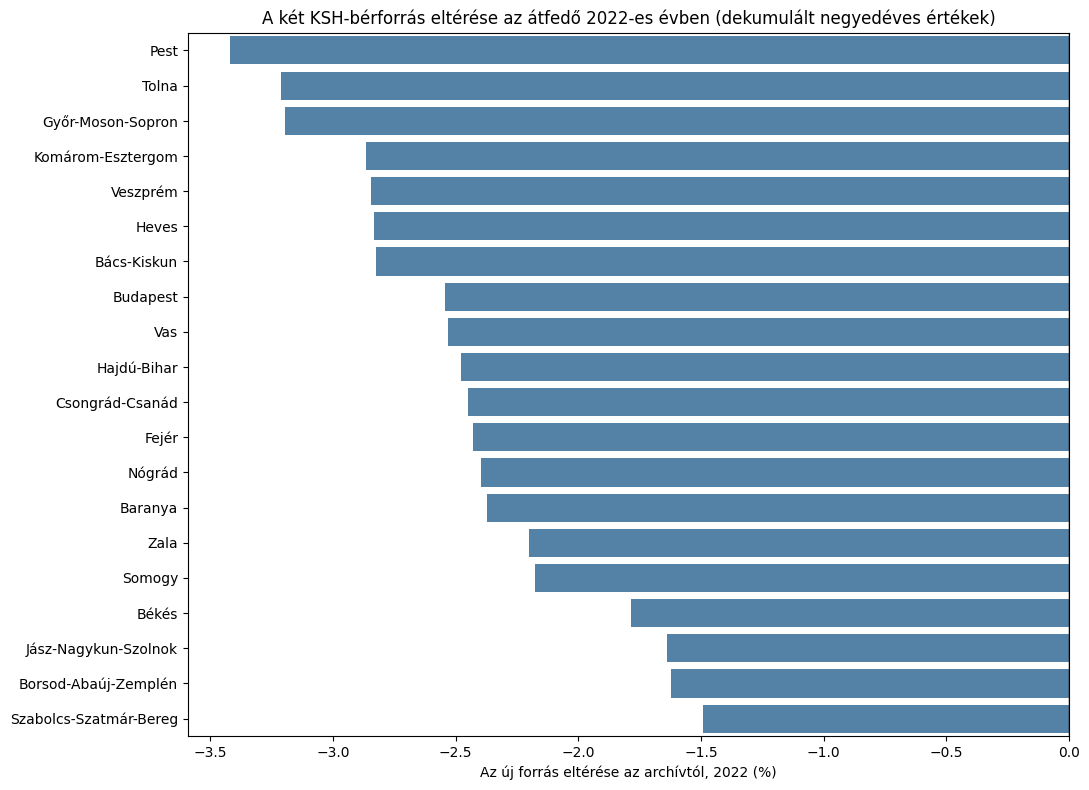

Mentve (robusztussági vizsgálathoz, a fő panelt NEM írja felül): c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed\KSH_Panel_FINAL_2018_2025_lancolt.csv


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

AREA = "Területi egység neve"
(OUT.parent / "figures").mkdir(parents=True, exist_ok=True)

# --- 1. A két forrás átfedése, ELŐJELESEN (a dolgozat eddig csak az abszolút eltérést közölte) ---------------
atf = archiv.merge(uj, on=["Dátum", AREA], how="inner")
atf["Eltérés_Ft (új − archív)"] = atf["Bruttó_átlagkereset_Új"] - atf["Bruttó_átlagkereset_Archív"]
atf["Eltérés_%"] = atf["Eltérés_Ft (új − archív)"] / atf["Bruttó_átlagkereset_Archív"] * 100
assert len(atf) == 80, "Az átfedés 20 terület × 4 negyedév = 80 megfigyelés kell legyen."

# --- 2. Ugyanez a DEKUMULÁLT negyedéves értékekre (a modell és az elemzések ezekkel dolgoznak) ---------------
def dekumulal(frame, value_col):
    f = frame.sort_values([AREA, "Dátum"]).copy()
    f["Év"], f["Negyedév"] = f["Dátum"].dt.year, f["Dátum"].dt.quarter
    prev = f.groupby([AREA, "Év"])[value_col].shift(1)
    f["Negyedéves"] = np.where(f["Negyedév"] == 1, f[value_col],
                               f["Negyedév"] * f[value_col] - (f["Negyedév"] - 1) * prev)
    return f[["Dátum", AREA, "Negyedéves"]]

arch_q = dekumulal(archiv[archiv["Dátum"].dt.year == 2022], "Bruttó_átlagkereset_Archív").rename(columns={"Negyedéves": "Archív_negyedéves"})
new_q = dekumulal(uj[uj["Dátum"].dt.year == 2022], "Bruttó_átlagkereset_Új").rename(columns={"Negyedéves": "Új_negyedéves"})
atf_q = arch_q.merge(new_q, on=["Dátum", AREA], how="inner")
atf_q["Eltérés_Ft (új − archív)"] = atf_q["Új_negyedéves"] - atf_q["Archív_negyedéves"]
atf_q["Eltérés_%"] = atf_q["Eltérés_Ft (új − archív)"] / atf_q["Archív_negyedéves"] * 100

def osszegzes(frame, label):
    return pd.Series({"Adat": label, "Átlag Ft": frame["Eltérés_Ft (új − archív)"].mean(),
                      "Átlag %": frame["Eltérés_%"].mean(), "Szórás %": frame["Eltérés_%"].std(),
                      "Min %": frame["Eltérés_%"].min(), "Max %": frame["Eltérés_%"].max(),
                      "Az új forrás kisebb (%)": (frame["Eltérés_Ft (új − archív)"] < 0).mean() * 100})
display(pd.DataFrame([osszegzes(atf, "kumulált (forrásfájl)"), osszegzes(atf_q, "dekumulált negyedéves")]).round(2))

# --- 3. Területenkénti kapcsoló arány (új / archív), a 2022-es átfedésből ----------------------------------------
ratio_by_area = (atf_q.groupby(AREA)["Új_negyedéves"].sum() / atf_q.groupby(AREA)["Archív_negyedéves"].sum()).rename("Arány_új_per_archív")
ratio_common = atf_q["Új_negyedéves"].sum() / atf_q["Archív_negyedéves"].sum()
print(f"Közös arány (új / archív): {ratio_common:.4f}")
display(ratio_by_area.sort_values().round(4).to_frame())

fig, ax = plt.subplots(figsize=(11, 8))
order = ratio_by_area.sort_values().index
sns.barplot(x=(ratio_by_area[order] - 1) * 100, y=order, color="steelblue", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Az új forrás eltérése az archívtól, 2022 (%)")
ax.set_ylabel("")
ax.set_title("A két KSH-bérforrás eltérése az átfedő 2022-es évben (dekumulált negyedéves értékek)")
plt.tight_layout()
fig.savefig(OUT.parent / "figures" / "forrasatfedes_elojeles_elteres.png", dpi=300, bbox_inches="tight")
plt.show()

atf.to_csv(OUT / "KSH_forrasatfedes_kumulalt.csv", index=False, encoding="utf-8-sig")
atf_q.to_csv(OUT / "KSH_forrasatfedes_dekumulalt.csv", index=False, encoding="utf-8-sig")

# --- 4. OPCIONÁLIS: LÁNCOLT (korrigált) PANEL ROBUSZTUSSÁGI VIZSGÁLATHOZ -----------------------------------------
# A 2018–2021-es (archív forrású) sorokat megszorozzuk a területi aránnyal. A kumulált és a dekumulált bér is lineárisan
# skálázódik, ezért a dekumulálás konzisztens marad. A származtatott változókat a 3. notebook képletei szerint újraszámoljuk.
def szarmaztatott_ujraszamolas(panel):
    p = panel.sort_values([AREA, "Dátum"]).reset_index(drop=True).copy()
    g_cum = p.groupby([AREA, "Év"])["Bruttó_átlagkereset_kumulált_HUF"]
    p["Előző_kumulált_bér"] = g_cum.shift(1)
    g = p.groupby(AREA)["Bruttó_átlagkereset_HUF"]
    p["Bér_Növekedés_QoQ"] = g.pct_change()
    p["Bér_Növekedés_YoY"] = g.pct_change(4)
    p["Jövő_Negyedévi_Bér"] = g.shift(-1)
    return p.sort_values(["Dátum", AREA]).reset_index(drop=True)

# Ellenőrzés: az újraszámolás az eredeti panelt reprodukálja (arány = 1 mellett)
ref = szarmaztatott_ujraszamolas(final_panel)
for col in ["Előző_kumulált_bér", "Bér_Növekedés_QoQ", "Bér_Növekedés_YoY", "Jövő_Negyedévi_Bér"]:
    assert np.allclose(ref[col], final_panel.sort_values(["Dátum", AREA]).reset_index(drop=True)[col], equal_nan=True), col

lancolt = final_panel.copy()
early = lancolt["Dátum"].dt.year <= 2021
scale = lancolt.loc[early, AREA].map(ratio_by_area)
for col in ["Bruttó_átlagkereset_kumulált_HUF", "Bruttó_átlagkereset_HUF"]:
    lancolt.loc[early, col] = lancolt.loc[early, col] * scale
lancolt = szarmaztatott_ujraszamolas(lancolt)
assert lancolt.shape == final_panel.shape
lancolt.to_csv(OUT / "KSH_Panel_FINAL_2018_2025_lancolt.csv", index=False, encoding="utf-8-sig")
print("Mentve (robusztussági vizsgálathoz, a fő panelt NEM írja felül):", OUT / "KSH_Panel_FINAL_2018_2025_lancolt.csv")

## Adatminőségi ellenőrzés

Ebben a részben a paneladatbázis teljességét, egyediségét,
időbeli konzisztenciáját és a hiányzó értékek indokoltságát
vizsgáljuk. A feature engineering következtében létrejövő
hiányzó értékeket elkülönítjük a valódi adathiányoktól.

In [6]:
# ADATMINŐSÉGI ÉS IDŐBELI KONZISZTENCIA-ELLENŐRZÉS

actual_missing_values = (
    final_panel
    .isna()
    .sum()
)
# A feature engineeringből következő,
# módszertanilag indokolt hiányzó értékek

expected_missing_values = {

    # Minden év első negyedévében nincs
    # előző, azonos éven belüli kumulált bér:
    # 8 év × 20 területi egység
    "Előző_kumulált_bér": 160,

    # Területenként az első megfigyeléshez
    # nincs előző negyedév
    "Bér_Növekedés_QoQ": 20,

    # Területenként az első négy negyedévhez
    # nincs előző évi azonos negyedév
    "Bér_Növekedés_YoY": 80,

    # Területenként az első megfigyeléshez
    # nincs előző munkanélküliségi ráta
    "Munkanélküliség_Delta": 20,

    # A legutolsó negyedév után nincs
    # következő negyedévi célérték
    "Jövő_Negyedévi_Bér": 20,

    # A legutolsó negyedévhez nincs céldátum
    "Cél_Dátum": 20
}
for column in final_panel.columns:

    expected_value = (
        expected_missing_values.get(
            column,
            0
        )
    )

    actual_value = int(
        actual_missing_values[column]
    )

    assert (
        actual_value
        == expected_value
    ), (
        f"Váratlan hiányzóérték-szám: {column}. "
        f"Várt: {expected_value}, "
        f"tényleges: {actual_value}."
    )

# CÉLVÁLTOZÓ IDŐBELI ELLENŐRZÉSE

target_check = (
    final_panel
    .sort_values(
        [
            "Területi egység neve",
            "Dátum"
        ]
    )
    .copy()
)

expected_target_wage = (
    target_check
    .groupby(
        "Területi egység neve"
    )[
        "Bruttó_átlagkereset_HUF"
    ]
    .shift(-1)
)

expected_target_date = (
    target_check
    .groupby(
        "Területi egység neve"
    )[
        "Dátum"
    ]
    .shift(-1)
)

assert np.allclose(
    target_check[
        "Jövő_Negyedévi_Bér"
    ],
    expected_target_wage,
    equal_nan=True
), (
    "A következő negyedévi célbér eltolása hibás."
)

assert (
    target_check[
        "Cél_Dátum"
    ]
    .equals(
        expected_target_date
    )
), (
    "A célnegyedév időbeli eltolása hibás."
)

# ADATMINŐSÉGI JELENTÉS

core_variables = [
    "Dátum",
    "Területi egység neve",
    "Munkanélküliségi_ráta_%",
    "Álláskeresők_száma",
    "Foglalkoztatottak, ezer fő",
    "Bruttó_átlagkereset_kumulált_HUF",
    "Bruttó_átlagkereset_HUF"
]

data_quality_report = pd.DataFrame(
    {
        "Mutató": [
            "Megfigyelések száma",
            "Változók száma",
            "Negyedévek száma",
            "Területi egységek száma",
            "Duplikált terület–negyedév párok",
            "Alapváltozók hiányzó értékei",
            "Legkorábbi negyedév",
            "Legkésőbbi negyedév",
            "Célváltozó időbeli eltolása"
        ],

        "Érték": [
            len(final_panel),
            final_panel.shape[1],
            final_panel["Dátum"].nunique(),
            final_panel[
                "Területi egység neve"
            ].nunique(),
            final_panel.duplicated(
                [
                    "Dátum",
                    "Területi egység neve"
                ]
            ).sum(),
            final_panel[
                core_variables
            ].isna().sum().sum(),
            str(
                final_panel[
                    "Dátum"
                ].min().to_period("Q")
            ),
            str(
                final_panel[
                    "Dátum"
                ].max().to_period("Q")
            ),
            "Megfelelő"
        ]
    }
)


print("ADATMINŐSÉGI ELLENŐRZÉS SIKERES")


display(
    data_quality_report
)

print(
    "\nHiányzó értékek változónként:"
)

display(
    actual_missing_values
    .rename("Hiányzó értékek")
    .to_frame()
)

data_quality_report.to_csv(
    OUT / "KSH_adatminosegi_jelentes.csv",
    index=False,
    encoding="utf-8-sig"
)

ADATMINŐSÉGI ELLENŐRZÉS SIKERES


,Mutató,Érték
0,Megfigyelések száma,640
1,Változók száma,15
2,Negyedévek száma,32
3,Területi egységek száma,20
4,Duplikált terület–negyedév párok,0
5,Alapváltozók hiányzó értékei,0
6,Legkorábbi negyedév,2018Q1
7,Legkésőbbi negyedév,2025Q4
8,Célváltozó időbeli eltolása,Megfelelő



Hiányzó értékek változónként:


,Hiányzó értékek
Dátum,0
Területi egység neve,0
Munkanélküliségi_ráta_%,0
Álláskeresők_száma,0
"Foglalkoztatottak, ezer fő",0
Bruttó_átlagkereset_kumulált_HUF,0
Év,0
Negyedév,0
Előző_kumulált_bér,160
Bruttó_átlagkereset_HUF,0


## Változójegyzék

A változójegyzék bemutatja a végleges paneladatbázis változóinak
jelentését, mértékegységét, elemzési szerepét és előállítási módját.

In [7]:
# VÁLTOZÓJEGYZÉK

variable_dictionary = pd.DataFrame(
    [
        {
            "Változó": "Dátum",
            "Jelentés": "A megfigyelés negyedévének kezdődátuma",
            "Mértékegység": "dátum",
            "Szerep": "időindex",
            "Előállítás": "KSH időszakjelölésből"
        },
        {
            "Változó": "Területi egység neve",
            "Jelentés": "Budapest vagy a 19 vármegye egyike",
            "Mértékegység": "kategória",
            "Szerep": "területi azonosító",
            "Előállítás": "KSH területi megnevezés"
        },
        {
            "Változó": "Munkanélküliségi_ráta_%",
            "Jelentés": "A területi munkanélküliségi ráta",
            "Mértékegység": "%",
            "Szerep": "gazdasági magyarázó változó",
            "Előállítás": "KSH-adat"
        },
        {
            "Változó": "Álláskeresők_száma",
            "Jelentés": "A nyilvántartott álláskeresők száma",
            "Mértékegység": "fő",
            "Szerep": "gazdasági magyarázó változó",
            "Előállítás": "KSH-adat"
        },
        {
            "Változó": "Foglalkoztatottak, ezer fő",
            "Jelentés": "A foglalkoztatottak becsült száma",
            "Mértékegység": "ezer fő",
            "Szerep": "gazdasági magyarázó változó",
            "Előállítás": "KSH-adat"
        },
        {
            "Változó": "Bruttó_átlagkereset_kumulált_HUF",
            "Jelentés": "Az adott éven belüli kumulált bruttó átlagkereset",
            "Mértékegység": "Ft",
            "Szerep": "forrás- és ellenőrző változó",
            "Előállítás": "Két KSH-bértábla egyesítéséből"
        },
        {
            "Változó": "Év",
            "Jelentés": "A megfigyelés naptári éve",
            "Mértékegység": "év",
            "Szerep": "időbeli azonosító",
            "Előállítás": "A Dátum változóból"
        },
        {
            "Változó": "Negyedév",
            "Jelentés": "A megfigyelés naptári negyedéve",
            "Mértékegység": "1–4",
            "Szerep": "szezonális azonosító",
            "Előállítás": "A Dátum változóból"
        },
        {
            "Változó": "Előző_kumulált_bér",
            "Jelentés": "Az előző negyedév azonos éven belüli kumulált bére",
            "Mértékegység": "Ft",
            "Szerep": "de-kumulálási segédváltozó",
            "Előállítás": "Területenként és évenként képzett késleltetés"
        },
        {
            "Változó": "Bruttó_átlagkereset_HUF",
            "Jelentés": "A de-kumulált, önálló negyedéves bruttó átlagkereset",
            "Mértékegység": "Ft",
            "Szerep": "központi gazdasági változó",
            "Előállítás": "A kumulált bér algebrai de-kumulálásából"
        },
        {
            "Változó": "Bér_Növekedés_QoQ",
            "Jelentés": "A bér változása az előző negyedévhez képest",
            "Mértékegység": "arány",
            "Szerep": "származtatott gazdasági változó",
            "Előállítás": "Területenkénti százalékos változás"
        },
        {
            "Változó": "Bér_Növekedés_YoY",
            "Jelentés": "A bér változása az előző év azonos negyedévéhez képest",
            "Mértékegység": "arány",
            "Szerep": "származtatott gazdasági változó",
            "Előállítás": "Területenkénti négy negyedéves változás"
        },
        {
            "Változó": "Munkanélküliség_Delta",
            "Jelentés": "A munkanélküliségi ráta negyedéves változása",
            "Mértékegység": "százalékpont",
            "Szerep": "származtatott gazdasági változó",
            "Előállítás": "Területenkénti első differencia"
        },
        {
            "Változó": "Jövő_Negyedévi_Bér",
            "Jelentés": "A következő negyedév de-kumulált bruttó átlagkeresete",
            "Mértékegység": "Ft",
            "Szerep": "előrejelzési célváltozó",
            "Előállítás": "A következő negyedévi bér területenkénti hozzárendelésével"
        },
        {
            "Változó": "Cél_Dátum",
            "Jelentés": "Az előrejelzés célnegyedévének kezdődátuma",
            "Mértékegység": "dátum",
            "Szerep": "előrejelzési célidőpont",
            "Előállítás": "Területenként következő negyedévi dátum"
        }
    ]
)

assert (
    set(variable_dictionary["Változó"])
    == set(final_panel.columns)
), (
    "A változójegyzék és az adatbázis oszlopai eltérnek."
)

display(
    variable_dictionary
)

variable_dictionary.to_csv(
    OUT / "KSH_valtozojegyzek.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A változójegyzék elmentve:",
    OUT / "KSH_valtozojegyzek.csv"
)

,Változó,Jelentés,Mértékegység,Szerep,Előállítás
0,Dátum,A megfigyelés negyedévének kezdődátuma,dátum,időindex,KSH időszakjelölésből
1,Területi egység neve,Budapest vagy a 19 vármegye egyike,kategória,területi azonosító,KSH területi megnevezés
2,Munkanélküliségi_ráta_%,A területi munkanélküliségi ráta,%,gazdasági magyarázó változó,KSH-adat
3,Álláskeresők_száma,A nyilvántartott álláskeresők száma,fő,gazdasági magyarázó változó,KSH-adat
4,"Foglalkoztatottak, ezer fő",A foglalkoztatottak becsült száma,ezer fő,gazdasági magyarázó változó,KSH-adat
5,Bruttó_átlagkereset_kumulált_HUF,Az adott éven belüli kumulált bruttó átlagkereset,Ft,forrás- és ellenőrző változó,Két KSH-bértábla egyesítéséből
6,Év,A megfigyelés naptári éve,év,időbeli azonosító,A Dátum változóból
7,Negyedév,A megfigyelés naptári negyedéve,1–4,szezonális azonosító,A Dátum változóból
8,Előző_kumulált_bér,Az előző negyedév azonos éven belüli kumulált ...,Ft,de-kumulálási segédváltozó,Területenként és évenként képzett késleltetés
9,Bruttó_átlagkereset_HUF,"A de-kumulált, önálló negyedéves bruttó átlagk...",Ft,központi gazdasági változó,A kumulált bér algebrai de-kumulálásából


A változójegyzék elmentve: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed\KSH_valtozojegyzek.csv


In [8]:
# KSH-FORRÁSJEGYZÉK

source_dictionary = pd.DataFrame(
    [
        {
            "Forrás": "KSH STADAT",
            "Táblakód": "20.2.2.5",
            "Fájlnév": UNEMP_FILE.name,
            "Felhasznált adat": "Munkanélküliségi ráta",
            "Szerep": "Gazdasági és munkaerőpiaci magyarázó változó"
        },
        {
            "Forrás": "KSH STADAT",
            "Táblakód": "20.2.2.6",
            "Fájlnév": LF_WORK.name,
            "Felhasznált adat": "Nyilvántartott álláskeresők száma",
            "Szerep": "Munkaerőpiaci magyarázó változó"
        },
        {
            "Forrás": "KSH STADAT",
            "Táblakód": "20.9.2.4",
            "Fájlnév": GROSS_FILE1.name,
            "Felhasznált adat": "Bruttó átlagkereset – archív adatforrás",
            "Szerep": "A korábbi időszak béradatainak forrása"
        },
        {
            "Forrás": "KSH STADAT",
            "Táblakód": "20.2.2.9",
            "Fájlnév": GROSS_FILE2.name,
            "Felhasznált adat": "Bruttó átlagkereset – új adatforrás",
            "Szerep": "Az újabb időszak béradatainak forrása"
        },
        {
            "Forrás": "KSH STADAT",
            "Táblakód": "20.2.2.1",
            "Fájlnév": ACTIVE_POP.name,
            "Felhasznált adat": "Foglalkoztatottak száma",
            "Szerep": "Munkaerőpiaci és területi magyarázó változó"
        }
    ]
)

display(
    source_dictionary
)

source_dictionary.to_csv(
    OUT / "KSH_forrasjegyzek.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A KSH-forrásjegyzék elmentve:",
    OUT / "KSH_forrasjegyzek.csv"
)

,Forrás,Táblakód,Fájlnév,Felhasznált adat,Szerep
0,KSH STADAT,20.2.2.5,stadat-mun0171-20.2.2.5-hu.csv,Munkanélküliségi ráta,Gazdasági és munkaerőpiaci magyarázó változó
1,KSH STADAT,20.2.2.6,stadat-mun0172-20.2.2.6-hu.csv,Nyilvántartott álláskeresők száma,Munkaerőpiaci magyarázó változó
2,KSH STADAT,20.9.2.4,stadat-mun0175-20.9.2.4-hu.csv,Bruttó átlagkereset – archív adatforrás,A korábbi időszak béradatainak forrása
3,KSH STADAT,20.2.2.9,stadat-mun0206-20.2.2.9-hu.csv,Bruttó átlagkereset – új adatforrás,Az újabb időszak béradatainak forrása
4,KSH STADAT,20.2.2.1,stadat-mun0161-20.2.2.1-hu.csv,Foglalkoztatottak száma,Munkaerőpiaci és területi magyarázó változó


A KSH-forrásjegyzék elmentve: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed\KSH_forrasjegyzek.csv
